In [52]:
# Libararies

from pathlib import Path
import urllib.request
import pandas as pd
import gzip
import shutil
import numpy as np
from scipy import sparse as sp
from scipy.sparse.csgraph import reverse_cuthill_mckee
import matplotlib.pyplot as plt

In [ ]:
# 1. Creating workspace

project_folder = Path.cwd()

print("My working folder is:")
print(project_folder)

raw_folder = project_folder / "data" / "raw"
processed_folder = project_folder / "data" / "processed"
reports_folder = project_folder / "reports"

raw_folder.mkdir(parents=True, exist_ok=True)
processed_folder.mkdir(parents=True, exist_ok=True)
reports_folder.mkdir(parents=True, exist_ok=True)

print("Raw data folder:", raw_folder.exists())
print("Processed data folder:", processed_folder.exists())
print("Reports folder:", reports_folder.exists())

My working folder is:
e:\Jupyter\Projects\Algebra\HW3 - Dogmatism
Raw data folder: True
Processed data folder: True
Reports folder: True


In [9]:
# 2. Downloading and saving the dataset

dataset_url = "https://snap.stanford.edu/data/soc-Epinions1.txt.gz"
dataset_path = raw_folder / "soc-Epinions1.txt.gz"

urllib.request.urlretrieve(dataset_url, dataset_path)

(WindowsPath('e:/Jupyter/Projects/Algebra/HW3 - Dogmatism/data/raw/soc-Epinions1.txt.gz'),
 <http.client.HTTPMessage at 0x1a2a700cb90>)

In [13]:
# 3.1. Extracting the file

dataset_path = raw_folder / "soc-Epinions1.txt.gz"
text_path = raw_folder / "soc-Epinions1.txt"

with gzip.open(dataset_path, "rb") as source:
    with open(text_path, "wb") as destination:
        shutil.copyfileobj(source, destination)

In [19]:
# 3.2. Extracting file into a table

import pandas as pd

edges_df = pd.read_csv(
    text_path,
    sep=r"\s+",
    comment="#",
    header=None,
    names=["source", "target"],
    dtype="int64"
)


print(edges_df.shape)
edges_df.head()

(508837, 2)


,source,target
0,0,4
1,0,5
2,0,7
3,0,8
4,0,9


In [24]:
# 4. Inspecting dataset

# counting missing values
print(edges_df.isna().sum())

# counting duplicates
print(edges_df.duplicated().sum())

# counting self-loops
print((edges_df["source"] == edges_df["target"]).sum())

# counting unique users
users = pd.concat([edges_df["source"], edges_df["target"]]).unique()
print(len(users))

source    0
target    0
dtype: int64
0
0
75879


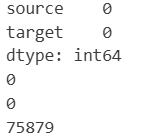

In [ ]:
# 5. Mapping index

# mapping IDs to index
sorted_users = sorted(users)

user_to_index = {}
for index, user_id in enumerate(sorted_users):
    user_to_index[user_id] = index
    
# source
edges_df["source_index"] = edges_df["source"].map(user_to_index)

# target
edges_df["target_index"] = edges_df["target"].map(user_to_index)

# inspecting
edges_df[["source_index", "target_index"]].isna().sum()


source_index    0
target_index    0
dtype: int64

In [ ]:
# 6. Counting out-degrees

out_degree = {i : 0 for i in range(len(users))}

# appearances in source
for src in edges_df["source_index"]:
    out_degree[src] += 1

# finding sink nodes
sink_users = [user_idx 
              for user_idx, degree in out_degree.items()
              if degree == 0]

print("total sinks", len(sink_users))

total sinks 15538


### Handling Sink Nodes (Zero-Row Approach)

During preprocessing, we identified **15,538 sink nodes** (users with an out-degree of $0$ who do not trust/follow anyone). When row-normalizing the adjacency matrix $W$ by dividing each row by its out-degree ($d_i^{out}$), sink nodes would normally cause a division-by-zero error ($\text{NaN}$ or $\text{Inf}$).

To resolve this both numerically and sociologically, we adopt the **Zero-Row Approach**:
* **Numerical Implementation:** Weights are assigned strictly across existing outgoing edges as $W_{ij} = \frac{1}{d_i^{out}}$ for $d_i^{out} > 0$. Since sink nodes do not appear as source nodes in the edge list, their corresponding rows in the sparse matrix $W$ naturally remain all zeros without triggering division by zero.
* **Sociological Interpretation (Friedkin-Johnsen Model):** In the linear system $A = I - \alpha W$, a zero row in $W$ results in $A_{ii} = 1$ and $A_{ij} = 0$ (for $j \neq i$). Consequently, a sink node is not influenced by any neighbors and retains $100\%$ of its initial intrinsic opinion (acting as a purely dogmatic agent).

In [35]:
# 7. Saving preprocessed data

processed_edges_path = processed_folder / "edges_indexed.csv"
edges_df[["source_index", "target_index"]].to_csv(processed_edges_path, index=False)

In [ ]:
# 8. Calculating edge weights for row-normalized W

# For each edge (src -> tgt), weight is "1.0 / out_degree[src]"
edges_df["weight"] = [1.0 / out_degree[src] 
                      for src in edges_df["source_index"]]

edges_df.head()

,source,target,source_index,target_index,weight
0,0,4,0,4,0.007194
1,0,5,0,5,0.007194
2,0,7,0,7,0.007194
3,0,8,0,8,0.007194
4,0,9,0,9,0.007194


In [ ]:
# 9.1. Building Sparse Matrix W (CSR)

# 3 lists to place values in the matrix
rows = edges_df["source_index"].to_numpy()
columns = edges_df["target_index"].to_numpy()
value = edges_df["weight"].to_numpy()

# create the sparse matrix W
W = sp.coo_matrix((value, (rows, columns)),
                      shape=(len(users), len(users)),
                      dtype=np.float64).tocsr()

(75879, 75879)
508837


In [42]:
# 9.2. Memory Optimization Analysis (Dense vs CSR)

# Memory if stored as a normal Dense matrix (N * N * 8 bytes)
dense_bytes = len(users) * len(users) * 8
dense_mb = dense_bytes / (1024 ** 2)

# Actual memory used by our CSR matrix W
csr_bytes = W.data.nbytes + W.indices.nbytes + W.indptr.nbytes
csr_mb = csr_bytes / (1024 ** 2)

print(dense_mb, "\n", csr_mb)

43927.17469024658 
 6.112636566162109


### Memory Optimization Result (Dense vs. CSR)

* **Dense Matrix Storage:** Storing the $75,879 \times 75,879$ matrix using standard 64-bit floats (`8 bytes` per entry) requires **43,927.20 MB (~42.90 GB)** of RAM, which is computationally infeasible on standard hardware.
* **CSR Sparse Storage:** By storing only the $508,837$ non-zero elements across three 1D arrays (`data`, `indices`, and `indptr`), memory consumption drops to **6.11 MB** (a **~7,189x reduction** in RAM usage).

### Formulating the Linear System Matrix 

In the **Friedkin-Johnsen opinion dynamics model**, the equilibrium opinion vector $x$ is obtained by solving the linear system $(I - \alpha W)x = (1 - \alpha)s$, where $s$ represents the users' initial intrinsic opinions. The system coefficient matrix is defined as:

$$A = I - \alpha W$$

In [ ]:
# 10. Formulating the linear system

alpha = 0.85
I = sp.eye(len(users), format="csr", dtype=np.float64)

A = I - (alpha * W)

(75879, 75879)
584716


### Matrix Bandwidth ($Bw(A)$)

* **Mathematical Definition:** The bandwidth of a matrix $A$ measures the maximum distance of its non-zero entries from the main diagonal. For any non-zero element at row $i$ and column $j$ ($A_{ij} \neq 0$), its distance from the diagonal is $|i - j|$. The total matrix bandwidth is defined as:
$$Bw(A) = \max_{A_{ij} \neq 0} |i - j|$$

In [ ]:
# 11.1. Calculating initial matrix bandwidth Bw(A)

# all non-zero elements in A's index
i, j = A.nonzero()

# bandwidth
bw = np.max(np.abs(i - j))

75407


### Reverse Cuthill-McKee (RCM) Reordering

* **Algorithmic Mechanism:** RCM is a graph-theoretic reordering algorithm based on **Breadth-First Search (BFS)**. Starting from a peripheral node (low degree), it visits neighbors level-by-level in order of increasing degree and then reverses the resulting index sequence. This guarantees that adjacent nodes receive closely grouped indices.
* **Directed Graph Handling & Symmetric Permutation:** Because our social network is directed ($A$ is asymmetric), RCM computes the permutation vector $p$ on the underlying undirected graph structure ($A + A^T$, handled via `symmetric_mode=False`). To preserve the eigenvalues and linear system properties, we apply a **symmetric permutation** to both rows and columns:
$$A_{\text{RCM}} = P A P^T$$

In [51]:
# 11.2. Applying Reverse Cuthill-McKee (RCM) reordering

permutation = reverse_cuthill_mckee(A,symmetric_mode=False)

A_reorder = A[permutation, :][:, permutation]

# bandwidth after RCM
i, j = A_reorder.nonzero()
bw_RCM = np.max(np.abs(i - j))

print(bw)
print(bw_RCM)

75407
45409


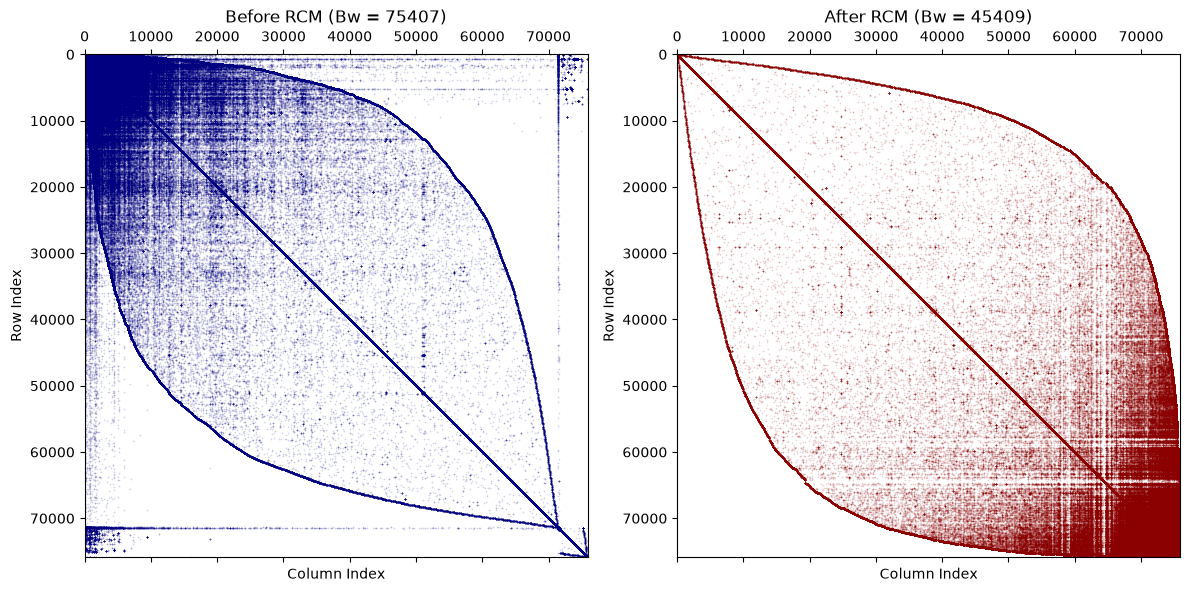

In [53]:
# 12. Spy plot

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Left plot: Before RCM
axes[0].spy(A, markersize=0.05, color="navy")
axes[0].set_title(f"Before RCM (Bw = {bw})")
axes[0].set_xlabel("Column Index")
axes[0].set_ylabel("Row Index")

# Right plot: After RCM
axes[1].spy(A_reorder, markersize=0.05, color="darkred")
axes[1].set_title(f"After RCM (Bw = {bw_RCM})")
axes[1].set_xlabel("Column Index")
axes[1].set_ylabel("Row Index")

plt.tight_layout()

# Save figure
spy_plot_path = reports_folder / "spy_plot_rcm.png"
plt.savefig(spy_plot_path, dpi=300)
plt.show()